# LSTM for Cyberbullying Detection

Multi-label classification on Jigsaw Toxic Comment dataset

In [ ]:
import torch

print("CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("Still running on CPU")

CUDA available: True
GPU: Tesla T4


**STEP 1**

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

DATA_PATH = '/content/drive/MyDrive/DL_cyber_data/train.csv'

Mounted at /content/drive


**STEP 2**

In [ ]:
import os

path = "/content/drive/MyDrive/DL_cyber_data/train.csv"

print("File exists:", os.path.exists(path))

if os.path.exists(path):
    print("File size (MB):", round(os.path.getsize(path) / (1024 * 1024), 2))

File exists: True
File size (MB): 65.62


**STEP 3**

In [ ]:
import pandas as pd

path = "/content/drive/MyDrive/DL_cyber_data/train.csv"

df = pd.read_csv(path, nrows=5)

print("Columns in dataset:")
print(df.columns.tolist())

print("\nFirst 5 rows:")
display(df)

Columns in dataset:
['id', 'comment_text', 'toxic', 'severe_toxic', 'obscene', 'threat', 'insult', 'identity_hate']

First 5 rows:


,id,comment_text,toxic,severe_toxic,obscene,threat,insult,identity_hate
0,0000997932d777bf,Explanation\nWhy the edits made under my usern...,0,0,0,0,0,0
1,000103f0d9cfb60f,D'aww! He matches this background colour I'm s...,0,0,0,0,0,0
2,000113f07ec002fd,"Hey man, I'm really not trying to edit war. It...",0,0,0,0,0,0
3,0001b41b1c6bb37e,"""\nMore\nI can't make any real suggestions on ...",0,0,0,0,0,0
4,0001d958c54c6e35,"You, sir, are my hero. Any chance you remember...",0,0,0,0,0,0


**STEP 4**

In [ ]:
import pandas as pd

path = "/content/drive/MyDrive/DL_cyber_data/train.csv"

df = pd.read_csv(path)

label_columns = [
    "toxic",
    "severe_toxic",
    "obscene",
    "threat",
    "insult",
    "identity_hate"
]

print("Dataset shape:", df.shape)
print("Missing comments:", df["comment_text"].isna().sum())

print("\nNumber of positive examples per category:")
print(df[label_columns].sum())

print("\nComments with at least one toxicity label:")
print((df[label_columns].sum(axis=1) > 0).sum())

print("\nCompletely non-toxic comments:")
print((df[label_columns].sum(axis=1) == 0).sum())

Dataset shape: (159571, 8)
Missing comments: 0

Number of positive examples per category:
toxic            15294
severe_toxic      1595
obscene           8449
threat             478
insult            7877
identity_hate     1405
dtype: int64

Comments with at least one toxicity label:
16225

Completely non-toxic comments:
143346


**STEP 5: Spliting  the dataset into training and validation sets**


In [ ]:
from sklearn.model_selection import train_test_split

label_columns = [
    "toxic",
    "severe_toxic",
    "obscene",
    "threat",
    "insult",
    "identity_hate"
]

X = df["comment_text"].astype(str)
y = df[label_columns].values

X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training comments:", len(X_train))
print("Validation comments:", len(X_val))
print("Training labels shape:", y_train.shape)
print("Validation labels shape:", y_val.shape)

Training comments: 127656
Validation comments: 31915
Training labels shape: (127656, 6)
Validation labels shape: (31915, 6)


**STEP 6: Text preprocessing**

 * LSTM needs text converted into sequences of numbers. We'll first clean the comments, then tokenize them and pad the sequences to a consistent length.
 * This step normalizes text while retaining apostrophes and replacing URLs and email addresses with placeholders.
* Important: We clean the training and validation text separately, but we won't fit the tokenizer on validation data. That avoids data leakage.

In [ ]:
import re
import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

# Basic text cleaning
def clean_text(text):
    text = text.lower() #coverts into small letters
    text = re.sub(r"http\S+|www\.\S+", " URL ", text) #in regular rexpression removes web addresses
    text = re.sub(r"\S+@\S+", " EMAIL ", text) #remove mentions and hastags
    text = re.sub(r"[^a-zA-Z0-9\s']", " ", text) #remove numbers and punchuvalities
    text = re.sub(r"\s+", " ", text).strip() #repeated whitespaces are removes
    return text

print("Cleaning training comments...")
X_train_clean = X_train.apply(clean_text)

print("Cleaning validation comments...")
X_val_clean = X_val.apply(clean_text)

print("Sample before:", X_train.iloc[0][:200])
print("Sample after: ", X_train_clean.iloc[0][:200])
print("Preprocessing completed!")

Cleaning training comments...
Cleaning validation comments...
Sample before: Grandma Terri Should Burn in Trash 
Grandma Terri is trash. I hate Grandma Terri. F%%K her to HELL! 71.74.76.40
Sample after:  grandma terri should burn in trash grandma terri is trash i hate grandma terri f k her to hell 71 74 76 40
Preprocessing completed!


* Your text preprocessing is working: comments are converted to lowercase, URLs and email addresses are replaced, and unwanted characters and extra spaces are removed.
* One note: the IP address in your example became separate numbers. That's okay for this initial version, but we may improve IP-address handling later.

**STEP 7: Build the tokenizer**
* Now we'll convert words into numerical sequences for the LSTM

tokenizers couns how many times each word appears in the entire datasett and it assaign samleer number to the most frquent words
ex: if "you" appears 10,000 times it get index 1

In [ ]:
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences # prepadding and post padding will be in pad_sequences

MAX_WORDS = 50000
MAX_LEN = 200

# Fit tokenizer ONLY on training comments
tokenizer = Tokenizer(
    num_words=MAX_WORDS,
    oov_token="<OOV>"
)
#oov --> out of vocabulary:it represented in numerical number that the word which is not presented in the tokenizers selected vocabulary
tokenizer.fit_on_texts(X_train_clean)

# Convert text to sequences
X_train_seq = tokenizer.texts_to_sequences(X_train_clean)
X_val_seq = tokenizer.texts_to_sequences(X_val_clean)

# Pad sequences to equal length
X_train_pad = pad_sequences(
    X_train_seq,
    maxlen=MAX_LEN,
    padding="post",
    truncating="post"
)

X_val_pad = pad_sequences(
    X_val_seq,
    maxlen=MAX_LEN,
    padding="post",
    truncating="post"
)

print("Vocabulary size:", min(len(tokenizer.word_index) + 1, MAX_WORDS))
print("Training shape:", X_train_pad.shape)
print("Validation shape:", X_val_pad.shape)

Vocabulary size: 50000
Training shape: (127656, 200)
Validation shape: (31915, 200)


* Our comments are now represented as numerical sequences, ready for the LSTM.

**STEP 8:**

**torch.cuda**: The specific module within the PyTorch library that enables Python developers to allocate tensors and run deep learning models on that physical GPU using CUDA

In [ ]:
import torch
print(f"CUDA available: {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"Device: {torch.cuda.get_device_name(0)}")

CUDA available: True
Device: Tesla T4


1 --> cleaned training comment(X_train_clean)

2 --> create tokenizers(set vacabulary limit = 50000 and oov taken)

3 --> fit tokenizers(learn words and assign interger ID's from training comments only)

4 --> padding(or)truncate(make every comment exactly 200 tokens long)

5 --> final numerical array(X_train_pad and X_val_pad)

ex:: padding sequence will be (you are a bad person)

                              12 8 5 27 41
padding sequence is (12,8,5,27,41,0,0,0,........200times)

**STEP 9:**

In [ ]:
import torch.nn as nn
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.metrics import precision_recall_fscore_support, accuracy_score
from torch.utils.data import Dataset, DataLoader
import matplotlib.pyplot as plt
import re
from collections import Counter
import time

**STEP 10: Define PyTorch text cleaning, vocabulary, and dataset**

In [ ]:
def clean_text(text):
    text = text.lower()
    text = re.sub(r'http\S+|www\S+', '', text)
    text = re.sub(r'@\w+|#\w+', '', text)
    text = re.sub(r'[^a-z\s]', '', text)
    return re.sub(r'\s+', ' ', text).strip()

def build_vocab(texts, max_vocab=10000):
    counter = Counter()
    for text in texts:
        counter.update(text.split())
    vocab = {'<PAD>': 0, '<UNK>': 1}
    #<PAD>-->padding,<UNK>-->represents a word not found in the vocabulary
    for word, _ in counter.most_common(max_vocab - 2):
        vocab[word] = len(vocab)
    return vocab

class TextDataset(Dataset):
    #coverts each comment in to a model input
    def __init__(self, texts, labels, vocab, max_len=100):
        self.texts = texts
        self.labels = labels
        self.vocab = vocab
        self.max_len = max_len

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, idx):
        #getting index of each word in the comment
        tokens = [self.vocab.get(w, 1) for w in self.texts[idx].split()]
        if len(tokens) < self.max_len:
            tokens += [0] * (self.max_len - len(tokens)) #adding zeros
        else:
            tokens = tokens[:self.max_len] # if the comment is containing the more than 200 then first 200 will consider only and rest are removed
        return torch.LongTensor(tokens), torch.FloatTensor(self.labels[idx])

**STEP 11: Define the BiLSTM model**

in input in forther steps we insert:


embedding_dim ---> no. of values represnting each token=100(reacives 100 features for each token

hidden_dim ---> hidden state size of each lstm direction=128

output_dim ---> no. of output categories = 6

n-layers ---> no. of stacked lstm layers=2

dropout ---> probability used for dropout = 0.3

In [ ]:
class LSTMClassifier(nn.Module):
    def __init__(self, vocab_size, embedding_dim, hidden_dim, output_dim, n_layers=2, dropout=0.3):
        super().__init__()
        #Embedding layer --->each number of id is converting into 100 vectors
        self.embedding = nn.Embedding(
            vocab_size, embedding_dim, padding_idx=0
        )
        #Bidirectional LSTM layer
        self.lstm = nn.LSTM(
            embedding_dim, hidden_dim, n_layers,
            batch_first=True,
            bidirectional=True,
            dropout=dropout #droupout is a regularization technique in depp learning used to prevent neural networks from overfitting
        )
        #Fully connected layer
        self.fc = nn.Linear(hidden_dim * 2, output_dim)
        #dropout rate is 0.3, meaning a 30% dropout probability for the activations to which this layer is applied.
        #Define the dropout layer --> droupout forcess evry neuron to learn useful features independently
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        embedded = self.dropout(self.embedding(x))
        _, (hidden, _) = self.lstm(embedded)
        hidden = torch.cat(
            [hidden[-2], hidden[-1]], dim=1
        )#combines the forword hidden state from top of lstm layers(-2) and backword(-1) hidden states
        #Produce the six output scores
        return self.fc(self.dropout(hidden))

 **STEP 12: Define the BiLSTM model**

In [ ]:
def accuracy_multilabel(preds, labels):
    preds = (torch.sigmoid(preds) > 0.5).float()
    return (preds == labels).float().mean()

def train_epoch(model, loader, optimizer, criterion, device):
    model.train()
    total_loss, total_acc = 0, 0
    for texts, labels in loader:
        texts, labels = texts.to(device), labels.to(device)
        optimizer.zero_grad()
        preds = model(texts)
        loss = criterion(preds, labels)
        loss.backward()
        optimizer.step()
        total_loss += loss.item()
        total_acc += accuracy_multilabel(preds, labels).item()
    return total_loss / len(loader), total_acc / len(loader)

def evaluate(model, loader, criterion, device):
    model.eval()
    total_loss, total_acc = 0, 0
    with torch.no_grad():
        for texts, labels in loader:
            texts, labels = texts.to(device), labels.to(device)
            preds = model(texts)
            total_loss += criterion(preds, labels).item()
            total_acc += accuracy_multilabel(preds, labels).item()
    return total_loss / len(loader), total_acc / len(loader)

def get_predictions(model, loader, device):
    model.eval()
    all_preds, all_labels = [], []
    with torch.no_grad():
        for texts, labels in loader:
            preds = torch.sigmoid(model(texts.to(device))) > 0.5
            all_preds.append(preds.cpu().numpy())
            all_labels.append(labels.numpy())
    return np.vstack(all_preds), np.vstack(all_labels)

**STEP 13: Load labels and inspect label counts**

In [ ]:
df = pd.read_csv(DATA_PATH)
label_cols = ['toxic', 'severe_toxic', 'obscene', 'threat', 'insult', 'identity_hate']
print(f"Total: {len(df)}")
print(f"\nLabels:\n{df[label_cols].sum()}")

Total: 159571

Labels:
toxic            15294
severe_toxic      1595
obscene           8449
threat             478
insult            7877
identity_hate     1405
dtype: int64


In [ ]:
df['num_labels'] = df[label_cols].sum(axis=1)
print("Number of labels per comment:")
print(df['num_labels'].value_counts().sort_index())

Number of labels per comment:
num_labels
0    143346
1      6360
2      3480
3      4209
4      1760
5       385
6        31
Name: count, dtype: int64


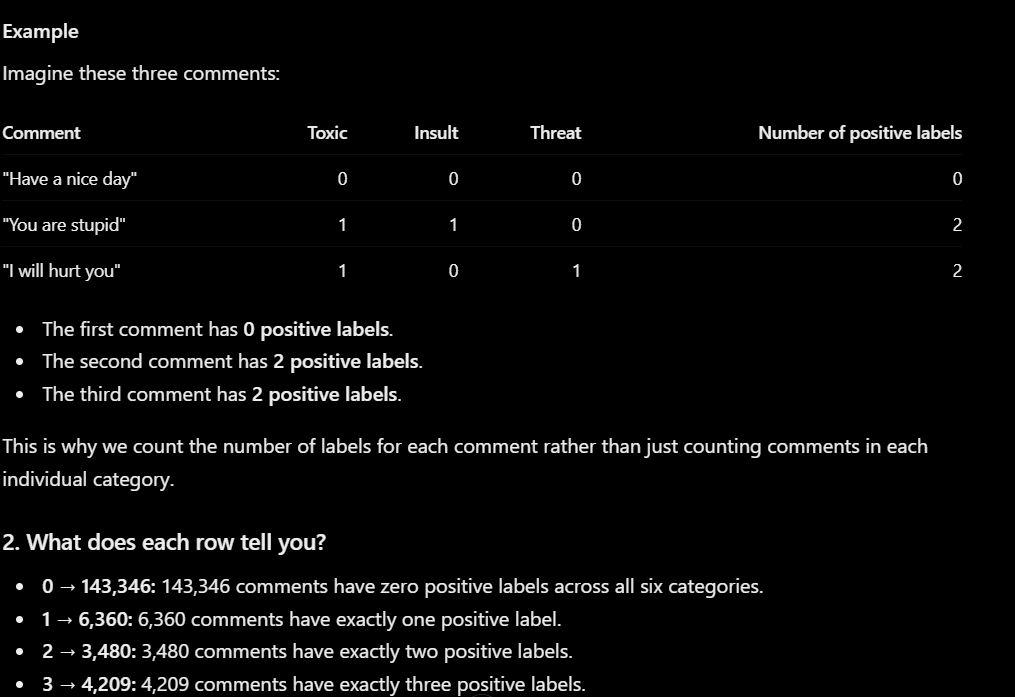

**STEP 14 : Clean text using the PyTorch pipeline**

In [ ]:
df['clean_text'] = df['comment_text'].apply(clean_text)

print("Sample comments:")
for i in range(2):
    print(f"\n{i+1}. {df['clean_text'].iloc[i][:100]}...")
    labels = [label_cols[j] for j in range(len(label_cols)) if df[label_cols[j]].iloc[i] == 1]
    print(f"   Labels: {labels if labels else ['clean']}")

Sample comments:

1. explanation why the edits made under my username hardcore metallica fan were reverted they werent va...
   Labels: ['clean']

2. daww he matches this background colour im seemingly stuck with thanks talk january utc...
   Labels: ['clean']


For example, if your original comment is:

"YOU are an IDIOT!!! Visit www.example.com"

After cleaning, it might become:

"you are an idiot visit"

**STEP 15 : Split data into training, validation, and test sets**

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    df['clean_text'].values, df[label_cols].values, test_size=0.2, random_state=42
)
vocab = build_vocab(X_train)
print(f"Vocab: {len(vocab)}, Train: {len(X_train)}, Test: {len(X_test)}")

Vocab: 10000, Train: 127656, Test: 31915


**STEP 16 : Create data loaders**

Your dataset contains 159,571 comments. Imagine sending every comment to the model in one go. That would require a lot of memory and could make training difficult.

In [ ]:
train_loader = DataLoader(TextDataset(X_train, y_train, vocab), batch_size=64, shuffle=True)
val_loader = DataLoader(TextDataset(X_val, y_val, vocab), batch_size=64, shuffle=False)
test_loader = DataLoader(TextDataset(X_test, y_test, vocab), batch_size=64, shuffle=False)

print(f"Train batches: {len(train_loader)}")
print(f"Validation batches: {len(val_loader)}")
print(f"Test batches: {len(test_loader)}")

Train batches: 1995
Validation batches: 499
Test batches: 499


forword hidden state shape:(32,128)

backword hidden state sahpw:(32,128)

(concatination) combined shape:(32,256)

1995 * 64 = 127,680

499 * 64 = 31,936


**STEP 17 : Initialize the model, optimizer, and loss**

'cuda' means use the GPU.

In [ ]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model = LSTMClassifier(
    len(vocab), 100, 128, len(label_cols)).to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
criterion = nn.BCEWithLogitsLoss()
print(f"Device: {device}\nParams: {sum(p.numel() for p in model.parameters())}")

Device: cuda
Params: 1632326


**STEP 18: Train the model**

In [ ]:
train_losses, test_losses, train_accs, test_accs = [], [], [], []
start = time.time()

for epoch in range(10):
    train_loss, train_acc = train_epoch(model, train_loader, optimizer, criterion, device)
    test_loss, test_acc = evaluate(model, test_loader, criterion, device)
    train_losses.append(train_loss)
    test_losses.append(test_loss)
    train_accs.append(train_acc)
    test_accs.append(test_acc)
    print(f'Epoch {epoch+1:02d} | Train Loss: {train_loss:.3f} Acc: {train_acc:.3f} | Test Loss: {test_loss:.3f} Acc: {test_acc:.3f}')

print(f"\nTime: {(time.time()-start)/60:.1f} min")

Epoch 01 | Train Loss: 0.095 Acc: 0.971 | Test Loss: 0.066 Acc: 0.979
Epoch 02 | Train Loss: 0.059 Acc: 0.980 | Test Loss: 0.053 Acc: 0.981
Epoch 03 | Train Loss: 0.053 Acc: 0.981 | Test Loss: 0.050 Acc: 0.982
Epoch 04 | Train Loss: 0.050 Acc: 0.982 | Test Loss: 0.050 Acc: 0.982
Epoch 05 | Train Loss: 0.047 Acc: 0.983 | Test Loss: 0.050 Acc: 0.983
Epoch 06 | Train Loss: 0.045 Acc: 0.983 | Test Loss: 0.049 Acc: 0.983
Epoch 07 | Train Loss: 0.043 Acc: 0.984 | Test Loss: 0.050 Acc: 0.983
Epoch 08 | Train Loss: 0.042 Acc: 0.984 | Test Loss: 0.049 Acc: 0.983
Epoch 09 | Train Loss: 0.040 Acc: 0.985 | Test Loss: 0.050 Acc: 0.983
Epoch 10 | Train Loss: 0.038 Acc: 0.986 | Test Loss: 0.052 Acc: 0.983

Time: 6.2 min


**STEP 19 : Evaluate on the held-out test set**

In [ ]:
y_pred, y_true = get_predictions(model, test_loader, device)
overall = precision_recall_fscore_support(y_true, y_pred, average='weighted', zero_division=0)
print(f"\nOverall - Precision: {overall[0]:.4f}, Recall: {overall[1]:.4f}, F1: {overall[2]:.4f}")
print(f"Accuracy: {accuracy_score(y_true, y_pred):.4f}")

print("\nPer-label F1:")
for i, label in enumerate(label_cols):
    f1 = precision_recall_fscore_support(y_true[:, i], y_pred[:, i], average='binary', zero_division=0)[2]
    print(f"{label}: {f1:.4f}")


Overall - Precision: 0.8364, Recall: 0.6595, F1: 0.7284
Accuracy: 0.9228

Per-label F1:
toxic: 0.7894
severe_toxic: 0.3875
obscene: 0.8109
threat: 0.2697
insult: 0.7059
identity_hate: 0.2248


overrall workflow is:

1) input tensor(batch_size,100)
2) embedding + dropout(batch_size,100,100)
3) twp-layers bilstm(128 hidden features per direction)
4) concatination(batch_size,256)
5) fully connected layers(batch_size,6)->six logics per comment

**STEP 20: Plot training and validation curves**

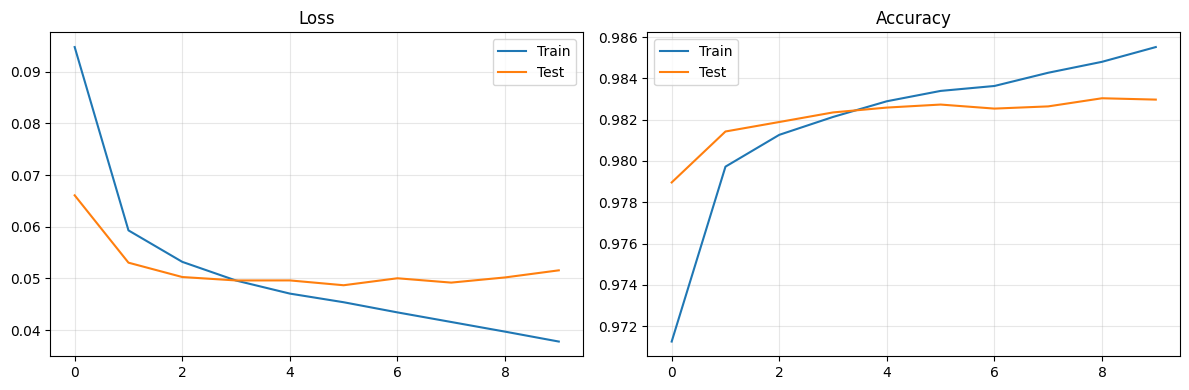

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(train_losses, label='Train')
axes[0].plot(test_losses, label='Test')
axes[0].set_title('Loss')
axes[0].legend()
axes[0].grid(alpha=0.3)
axes[1].plot(train_accs, label='Train')
axes[1].plot(test_accs, label='Test')
axes[1].set_title('Accuracy')
axes[1].legend()
axes[1].grid(alpha=0.3)
plt.tight_layout()
plt.show()

**Save the trained model**

In [ ]:
import json

OUTPUT_DIR = '/content/drive/MyDrive/DL_cyber_data/model_output'
os.makedirs(OUTPUT_DIR, exist_ok=True)

torch.save({
    'model_state_dict': model.state_dict(),
    'vocab_size': len(vocab),
    'embedding_dim': 100,
    'hidden_dim': 128,
    'output_dim': len(label_cols),
    'n_layers': 2,
    'dropout': 0.3,
    'max_len': 100
}, os.path.join(OUTPUT_DIR, 'lstm_model.pt'))

with open(os.path.join(OUTPUT_DIR, 'vocabulary.json'), 'w', encoding='utf-8') as f:
    json.dump(vocab, f, ensure_ascii=False)

with open(os.path.join(OUTPUT_DIR, 'label_columns.json'), 'w', encoding='utf-8') as f:
    json.dump(label_cols, f)

print("Model, vocabulary, and label names saved to:", OUTPUT_DIR)

Model, vocabulary, and label names saved to: /content/drive/MyDrive/DL_cyber_data/model_output


In [ ]:
# ============================================
# TOXIC COMMENT DETECTION — PREDICTION DEMO
# Loads the saved model; does NOT retrain
# ============================================

import os
import re
import json
import torch
import torch.nn as nn

from google.colab import drive

# 1. Connect Google Drive if it is not already mounted
if not os.path.exists('/content/drive/MyDrive'):
    drive.mount('/content/drive')

# 2. Load saved files
OUTPUT_DIR = '/content/drive/MyDrive/DL_cyber_data/model_output'

MODEL_PATH = os.path.join(OUTPUT_DIR, 'lstm_model.pt')
VOCAB_PATH = os.path.join(OUTPUT_DIR, 'vocabulary.json')
LABEL_PATH = os.path.join(OUTPUT_DIR, 'label_columns.json')

for path in [MODEL_PATH, VOCAB_PATH, LABEL_PATH]:
    if not os.path.exists(path):
        raise FileNotFoundError(
            f"Missing file: {path}\n"
            "Run your notebook's model-saving section first."
        )

with open(VOCAB_PATH, 'r', encoding='utf-8') as f:
    vocab = json.load(f)

with open(LABEL_PATH, 'r', encoding='utf-8') as f:
    label_cols = json.load(f)

# 3. Use the same cleaning method as the PyTorch training pipeline
def clean_text(text):
    text = str(text).lower()
    text = re.sub(r'http\S+|www\S+', '', text)
    text = re.sub(r'@\w+|#\w+', '', text)
    text = re.sub(r'[^a-z\s]', '', text)
    return re.sub(r'\s+', ' ', text).strip()

# 4. Convert a new comment into the same 100-token input format
MAX_LEN = 100

def encode_comment(comment):
    cleaned = clean_text(comment)
    tokens = [vocab.get(word, 1) for word in cleaned.split()]

    if len(tokens) < MAX_LEN:
        tokens += [0] * (MAX_LEN - len(tokens))
    else:
        tokens = tokens[:MAX_LEN]

    return torch.tensor([tokens], dtype=torch.long)

# 5. Recreate the exact model architecture and load saved weights
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

checkpoint = torch.load(
    MODEL_PATH,
    map_location=device,
    weights_only=True
)

model = LSTMClassifier(
    vocab_size=checkpoint['vocab_size'],
    embedding_dim=checkpoint['embedding_dim'],
    hidden_dim=checkpoint['hidden_dim'],
    output_dim=checkpoint['output_dim'],
    n_layers=checkpoint['n_layers'],
    dropout=checkpoint['dropout']
).to(device)

model.load_state_dict(checkpoint['model_state_dict'])
model.eval()

print("Model loaded successfully!")
print("Device:", device)
print("Labels:", label_cols)

# 6. Predict the toxicity labels for any comment
def predict_toxicity(comment, threshold=0.5):
    input_tensor = encode_comment(comment).to(device)

    with torch.no_grad():
        logits = model(input_tensor)
        probabilities = torch.sigmoid(logits)[0].cpu().tolist()

    print("\nComment:", comment)
    print("-" * 45)

    for label, probability in zip(label_cols, probabilities):
        prediction = "YES" if probability >= threshold else "NO"
        print(f"{label:15s}: {prediction:3s} | Score: {probability:.4f}")

    if any(p >= threshold for p in probabilities):
        print("\nOverall result: Potentially toxic")
    else:
        print("\nOverall result: No toxicity label crossed the threshold")

# 7. Try your own comment here
my_comment = "You are an idiot and nobody likes you."
predict_toxicity(my_comment)

Model loaded successfully!
Device: cuda
Labels: ['toxic', 'severe_toxic', 'obscene', 'threat', 'insult', 'identity_hate']

Comment: You are an idiot and nobody likes you.
---------------------------------------------
toxic          : YES | Score: 0.9865
severe_toxic   : NO  | Score: 0.0257
obscene        : NO  | Score: 0.4060
threat         : NO  | Score: 0.0060
insult         : YES | Score: 0.8787
identity_hate  : NO  | Score: 0.0379

Overall result: Potentially toxic


In [ ]:
# ============================================
# TOXIC COMMENT DETECTION — PREDICTION DEMO
# Loads the saved model; does NOT retrain
# ============================================

import os
import re
import json
import torch
import torch.nn as nn

from google.colab import drive

# 1. Connect Google Drive if it is not already mounted
if not os.path.exists('/content/drive/MyDrive'):
    drive.mount('/content/drive')

# 2. Load saved files
OUTPUT_DIR = '/content/drive/MyDrive/DL_cyber_data/model_output'

MODEL_PATH = os.path.join(OUTPUT_DIR, 'lstm_model.pt')
VOCAB_PATH = os.path.join(OUTPUT_DIR, 'vocabulary.json')
LABEL_PATH = os.path.join(OUTPUT_DIR, 'label_columns.json')

for path in [MODEL_PATH, VOCAB_PATH, LABEL_PATH]:
    if not os.path.exists(path):
        raise FileNotFoundError(
            f"Missing file: {path}\n"
            "Run your notebook's model-saving section first."
        )

with open(VOCAB_PATH, 'r', encoding='utf-8') as f:
    vocab = json.load(f)

with open(LABEL_PATH, 'r', encoding='utf-8') as f:
    label_cols = json.load(f)

# 3. Use the same cleaning method as the PyTorch training pipeline
def clean_text(text):
    text = str(text).lower()
    text = re.sub(r'http\S+|www\S+', '', text)
    text = re.sub(r'@\w+|#\w+', '', text)
    text = re.sub(r'[^a-z\s]', '', text)
    return re.sub(r'\s+', ' ', text).strip()

# 4. Convert a new comment into the same 100-token input format
MAX_LEN = 100

def encode_comment(comment):
    cleaned = clean_text(comment)
    tokens = [vocab.get(word, 1) for word in cleaned.split()]

    if len(tokens) < MAX_LEN:
        tokens += [0] * (MAX_LEN - len(tokens))
    else:
        tokens = tokens[:MAX_LEN]

    return torch.tensor([tokens], dtype=torch.long)

# 5. Recreate the exact model architecture and load saved weights
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

checkpoint = torch.load(
    MODEL_PATH,
    map_location=device,
    weights_only=True
)

model = LSTMClassifier(
    vocab_size=checkpoint['vocab_size'],
    embedding_dim=checkpoint['embedding_dim'],
    hidden_dim=checkpoint['hidden_dim'],
    output_dim=checkpoint['output_dim'],
    n_layers=checkpoint['n_layers'],
    dropout=checkpoint['dropout']
).to(device)

model.load_state_dict(checkpoint['model_state_dict'])
model.eval()

print("Model loaded successfully!")
print("Device:", device)
print("Labels:", label_cols)

# 6. Predict the toxicity labels for any comment
def predict_toxicity(comment, threshold=0.5):
    input_tensor = encode_comment(comment).to(device)

    with torch.no_grad():
        logits = model(input_tensor)
        probabilities = torch.sigmoid(logits)[0].cpu().tolist()

    print("\nComment:", comment)
    print("-" * 45)

    for label, probability in zip(label_cols, probabilities):
        prediction = "YES" if probability >= threshold else "NO"
        print(f"{label:15s}: {prediction:3s} | Score: {probability:.4f}")

    if any(p >= threshold for p in probabilities):
        print("\nOverall result: Potentially toxic")
    else:
        print("\nOverall result: No toxicity label crossed the threshold")

# 7. Try your own comment here
my_comment = "Have a nice day!"
predict_toxicity(my_comment)

Model loaded successfully!
Device: cuda
Labels: ['toxic', 'severe_toxic', 'obscene', 'threat', 'insult', 'identity_hate']

Comment: Have a nice day!
---------------------------------------------
toxic          : NO  | Score: 0.0005
severe_toxic   : NO  | Score: 0.0000
obscene        : NO  | Score: 0.0001
threat         : NO  | Score: 0.0000
insult         : NO  | Score: 0.0000
identity_hate  : NO  | Score: 0.0000

Overall result: No toxicity label crossed the threshold


In [ ]:
# ============================================
# TOXIC COMMENT DETECTION — PREDICTION DEMO
# Loads the saved model; does NOT retrain
# ============================================

import os
import re
import json
import torch
import torch.nn as nn

from google.colab import drive

# 1. Connect Google Drive if it is not already mounted
if not os.path.exists('/content/drive/MyDrive'):
    drive.mount('/content/drive')

# 2. Load saved files
OUTPUT_DIR = '/content/drive/MyDrive/DL_cyber_data/model_output'

MODEL_PATH = os.path.join(OUTPUT_DIR, 'lstm_model.pt')
VOCAB_PATH = os.path.join(OUTPUT_DIR, 'vocabulary.json')
LABEL_PATH = os.path.join(OUTPUT_DIR, 'label_columns.json')

for path in [MODEL_PATH, VOCAB_PATH, LABEL_PATH]:
    if not os.path.exists(path):
        raise FileNotFoundError(
            f"Missing file: {path}\n"
            "Run your notebook's model-saving section first."
        )

with open(VOCAB_PATH, 'r', encoding='utf-8') as f:
    vocab = json.load(f)

with open(LABEL_PATH, 'r', encoding='utf-8') as f:
    label_cols = json.load(f)

# 3. Use the same cleaning method as the PyTorch training pipeline
def clean_text(text):
    text = str(text).lower()
    text = re.sub(r'http\S+|www\S+', '', text)
    text = re.sub(r'@\w+|#\w+', '', text)
    text = re.sub(r'[^a-z\s]', '', text)
    return re.sub(r'\s+', ' ', text).strip()

# 4. Convert a new comment into the same 100-token input format
MAX_LEN = 100

def encode_comment(comment):
    cleaned = clean_text(comment)
    tokens = [vocab.get(word, 1) for word in cleaned.split()]

    if len(tokens) < MAX_LEN:
        tokens += [0] * (MAX_LEN - len(tokens))
    else:
        tokens = tokens[:MAX_LEN]

    return torch.tensor([tokens], dtype=torch.long)

# 5. Recreate the exact model architecture and load saved weights
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

checkpoint = torch.load(
    MODEL_PATH,
    map_location=device,
    weights_only=True
)

model = LSTMClassifier(
    vocab_size=checkpoint['vocab_size'],
    embedding_dim=checkpoint['embedding_dim'],
    hidden_dim=checkpoint['hidden_dim'],
    output_dim=checkpoint['output_dim'],
    n_layers=checkpoint['n_layers'],
    dropout=checkpoint['dropout']
).to(device)

model.load_state_dict(checkpoint['model_state_dict'])
model.eval()

print("Model loaded successfully!")
print("Device:", device)
print("Labels:", label_cols)

# 6. Predict the toxicity labels for any comment
def predict_toxicity(comment, threshold=0.5):
    input_tensor = encode_comment(comment).to(device)

    with torch.no_grad():
        logits = model(input_tensor)
        probabilities = torch.sigmoid(logits)[0].cpu().tolist()

    print("\nComment:", comment)
    print("-" * 45)

    for label, probability in zip(label_cols, probabilities):
        prediction = "YES" if probability >= threshold else "NO"
        print(f"{label:15s}: {prediction:3s} | Score: {probability:.4f}")

    if any(p >= threshold for p in probabilities):
        print("\nOverall result: Potentially toxic")
    else:
        print("\nOverall result: No toxicity label crossed the threshold")

# 7. Try your own comment here
my_comment = "You are a pathetic idiot and nobody wants you here."
predict_toxicity(my_comment)

Model loaded successfully!
Device: cuda
Labels: ['toxic', 'severe_toxic', 'obscene', 'threat', 'insult', 'identity_hate']

Comment: You are a pathetic idiot and nobody wants you here.
---------------------------------------------
toxic          : YES | Score: 0.9941
severe_toxic   : NO  | Score: 0.0555
obscene        : YES | Score: 0.5958
threat         : NO  | Score: 0.0126
insult         : YES | Score: 0.9333
identity_hate  : NO  | Score: 0.0700

Overall result: Potentially toxic
